# 02 · Escassez controlada no Oxford-IIIT Pet

Objetivo: ver como cada regime se comporta quando há poucas imagens por classe, antes de ir para o dataset das gatas (20–30 imagens por classe).

Para cada k ∈ {5, 10, 20, 30} imagens por raça e cada seed (0, 1, 2), o treino é sorteado do mesmo treino do baseline, e os 3 modelos × 3 regimes treinam por 1000 passos, sem validação. O modelo final é avaliado uma vez no teste completo (3.669 imagens). São 108 treinos.

O treino roda fora do notebook (`src/fewshot.py`, ~13 h). Este notebook só lê `results/fewshot/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent  # o notebook roda de dentro de notebooks/
sys.path.insert(0, str(ROOT / "src"))
from models import BACKBONES, REGIMES

RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"

# Mesmo estilo do notebook 01: figuras do tamanho de uma coluna do IEEE
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7})
COLUMN_WIDTH = 3.5
TITLES = {"resnet18": "ResNet18", "mobilenet_v2": "MobileNetV2", "dinov2_vits14": "ViT-S/14 DINOv2"}
REGIME_NAMES = {"linear": "Linear", "partial": "Parcial", "full": "Completo"}
COLORS = {"linear": "#2a78d6", "partial": "#eb6834", "full": "#1baf7a"}
MARKERS = {"linear": "o", "partial": "s", "full": "^"}
KS = (5, 10, 20, 30)

runs = pd.read_csv(RESULTS / "fewshot" / "summary.csv")
base = pd.read_csv(RESULTS / "summary.csv").query("dataset == 'pets' and experiment == 'baseline'")

# Conferência: cada combinação modelo × regime × k deve ter as 3 seeds
print(len(runs), "treinos")
runs.groupby(["backbone", "regime", "k"]).size().unstack("k")

108 treinos


/Users/eduardaveras/Mestrado/gatinhas-dl/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


k                      5   10  20  30
backbone      regime                 
dinov2_vits14 full      3   3   3   3
              linear    3   3   3   3
              partial   3   3   3   3
mobilenet_v2  full      3   3   3   3
              linear    3   3   3   3
              partial   3   3   3   3
resnet18      full      3   3   3   3
              linear    3   3   3   3
              partial   3   3   3   3

## 1. Acurácia no teste por k

Média entre as 3 seeds (%). A última coluna é o baseline com o Pets completo (~80 imagens por raça, escolhendo a época pela validação), só como referência. Os desvios entre seeds aparecem como faixas na figura 1.1.

In [2]:
stats = runs.groupby(["backbone", "regime", "k"])["test_acc"].agg(["mean", "std"]).mul(100)
table = stats["mean"].unstack("k")
table["completo"] = 100 * base.set_index(["backbone", "regime"])["test_acc"]
print(f"maior desvio entre seeds: {stats['std'].max():.1f} pp")
table.reindex(pd.MultiIndex.from_product([BACKBONES, REGIMES])).round(1)

maior desvio entre seeds: 2.6 pp


k                         5    10    20    30  completo
resnet18      linear   80.4  85.5  87.6  88.7      89.0
              partial  68.9  79.9  84.7  87.0      89.8
              full     64.1  76.1  83.0  86.0      89.7
mobilenet_v2  linear   80.4  86.2  88.6  89.4      90.5
              partial  73.3  82.0  86.2  88.3      90.8
              full     68.6  79.6  85.3  87.6      90.3
dinov2_vits14 linear   85.6  90.5  92.8  93.5      94.7
              partial  83.5  90.5  92.7  93.6      95.2
              full     81.0  88.8  91.6  93.0      94.5

### 1.1 Curvas acurácia × k

Uma figura por modelo, com os três regimes. A faixa é ± 1 desvio entre as seeds. O ponto isolado à direita é o baseline no Pets completo (não ligado às curvas, porque foi treinado com outro protocolo).

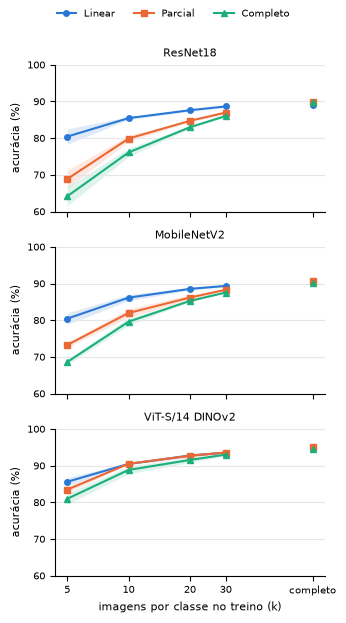

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(COLUMN_WIDTH, 6.2), sharex=True, sharey=True)
for ax, b in zip(axes, BACKBONES):
    for r in REGIMES:
        s = stats.loc[(b, r)]
        ax.plot(KS, s["mean"], color=COLORS[r], marker=MARKERS[r], ms=4, lw=1.5, label=REGIME_NAMES[r])
        ax.fill_between(KS, s["mean"] - s["std"], s["mean"] + s["std"], color=COLORS[r], alpha=0.15, lw=0)
        full_pets = 100 * base.query("backbone == @b and regime == @r")["test_acc"].item()
        ax.plot(80, full_pets, color=COLORS[r], marker=MARKERS[r], ms=4, ls="none")
    ax.set_title(TITLES[b])
    ax.set_ylabel("acurácia (%)")
    ax.set_ylim(60, 100)
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xscale("log")
axes[-1].set_xticks([*KS, 80], [*map(str, KS), "completo"])
axes[-1].minorticks_off()
axes[-1].set_xlabel("imagens por classe no treino (k)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(FIGURES / "fewshot_curvas.png", dpi=300)

## 2. H1: com poucos dados, o linear supera o ajuste completo?

Quantos pontos percentuais o linear fica à frente do ajuste completo (média das seeds). Como cada seed sorteia as mesmas imagens para todos os regimes, dá para comparar seed a seed.

In [4]:
acc = runs.pivot_table(index=["backbone", "k", "seed"], columns="regime", values="test_acc")
diff = 100 * (acc["linear"] - acc["full"])
print(f"o linear venceu em {(diff > 0).sum()} de {len(diff)} comparações (modelo × k × seed)")
diff.groupby(["backbone", "k"]).mean().unstack("k").reindex(BACKBONES).round(1)

o linear venceu em 36 de 36 comparações (modelo × k × seed)


k,5,10,20,30
backbone,,,,
resnet18,16.3,9.4,4.6,2.6
mobilenet_v2,11.8,6.5,3.3,1.8
dinov2_vits14,4.6,1.6,1.2,0.5


## 3. H2: quem sofre mais no ajuste completo, CNN ou ViT?

A hipótese era que as CNNs sofreriam menos. A tabela acima já responde: com k=5, o ajuste completo custa ~16 pontos na ResNet18, ~12 na MobileNetV2 e ~5 no DINOv2, ou seja, o contrário.

Uma diferença de receita pesa aqui: a LR do backbone do DINOv2 é 10× menor (1e-5 contra 1e-4, escolhida no baseline porque 1e-4 destruía as features). Com passos menores, os pesos pré-treinados mudam menos, e isso também protege contra o *overfitting*. Por isso, o resultado mostra que **o DINOv2, com a LR que ele precisa**, sofre menos, e não separa o efeito da arquitetura do efeito da LR.

## 4. Memorização: acurácia de treino × teste

Com k=5, acurácia de treino na última época (com aumento de dados) e no teste, médias das seeds (%). Todos os regimes chegam perto de 100% no treino; o que muda é quanto disso vale no teste.

In [5]:
runs["train_acc_final"] = [
    pd.read_csv(RESULTS / "fewshot" / "csv" / f"{r.backbone}_{r.regime}_k{r.k}_s{r.seed}.csv")["train_acc"].iloc[-1]
    for r in runs.itertuples()
]
mem = (runs.query("k == 5").groupby(["backbone", "regime"])[["train_acc_final", "test_acc"]].mean().mul(100)
       .rename(columns={"train_acc_final": "treino", "test_acc": "teste"}))
mem.reindex(pd.MultiIndex.from_product([BACKBONES, REGIMES])).round(1)

treino  teste
resnet18      linear     97.8   80.4
              partial    99.1   68.9
              full       98.7   64.1
mobilenet_v2  linear     98.7   80.4
              partial    99.3   73.3
              full       99.6   68.6
dinov2_vits14 linear     99.1   85.6
              partial    99.3   83.5
              full       99.5   81.0

## 5. H3: no linear, o ViT supera as CNNs?

Acurácia dos três modelos no regime linear (média ± desvio entre seeds), e a diferença entre o DINOv2 e a melhor CNN (pontos percentuais).

k,5,10,20,30
DINOv2,85.6,90.5,92.8,93.5
melhor CNN,80.4,86.2,88.6,89.4
diferença (pp),5.2,4.3,4.2,4.2


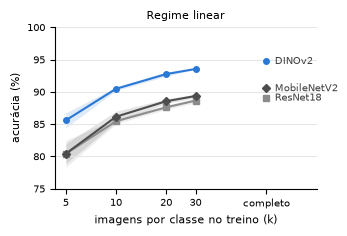

In [6]:
# Só o regime linear. As CNNs em cinza e o ViT em destaque, já que a pergunta é ViT × CNNs.
# (As cores aqui identificam modelos, não regimes como nas figuras anteriores.)
MODEL_STYLE = {"resnet18": dict(color="0.55", marker="s"), "mobilenet_v2": dict(color="0.3", marker="D"),
               "dinov2_vits14": dict(color="#2a78d6", marker="o")}

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.4))
for b in BACKBONES:
    s = stats.loc[(b, "linear")]
    style = MODEL_STYLE[b]
    ax.plot(KS, s["mean"], lw=1.5, ms=4, **style)
    ax.fill_between(KS, s["mean"] - s["std"], s["mean"] + s["std"], color=style["color"], alpha=0.15, lw=0)
    full_pets = 100 * base.query("backbone == @b and regime == 'linear'")["test_acc"].item()
    ax.plot(80, full_pets, ms=4, ls="none", **style)
    # Rótulo direto no fim de cada curva, no lugar da legenda
    ax.annotate(TITLES[b].replace("ViT-S/14 ", ""), (80, full_pets), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=7, color="0.25")
ax.set_xscale("log")
ax.set_xticks([*KS, 80], [*map(str, KS), "completo"])
ax.minorticks_off()
ax.set_xlim(4.3, 160)
ax.set_ylim(75, 100)
ax.set_xlabel("imagens por classe no treino (k)")
ax.set_ylabel("acurácia (%)")
ax.set_title("Regime linear")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / "fewshot_linear.png", dpi=300)

lin = stats.xs("linear", level="regime")["mean"].unstack("k")
h3 = pd.DataFrame({"DINOv2": lin.loc["dinov2_vits14"],
                   "melhor CNN": lin.drop("dinov2_vits14").max(),
                   "diferença (pp)": lin.loc["dinov2_vits14"] - lin.drop("dinov2_vits14").max()})
h3.round(1).T